notebooks/eda.ipynb:
 - Visualizations and descriptive stats.
 - Missingness analysis.
 - Correlation heatmaps, scatterplots, outlier checks.
 - Exploratory lag analysis (ACF/PACF, lag vs. target plots).

In [1]:
date = "200202"

if date:
    theta_path = "../data_excerpt/theta/theta2pvu_" + date + ".grib"
    uv_path = "../data_excerpt/uv/uv300_" + date + ".grib"
else:
    theta_path = "../data_excerpt/theta/theta2pvu_199812.grib"
    uv_path = "../data_excerpt/uv/uv300_199812.grib"

In [ ]:
import sys
import numpy as np

# Make sure Python can find plot_era40.py in the parent directory
sys.path.append("..")
from plot_era40 import NAMES, read

# 1. First, just get available times in the current grib
# If calling read without a time returns times as the 3rd element:
_, _, theta_times, _ = read(theta_path, NAMES["theta"])
_, _, uv_times, _ = read(uv_path, NAMES["uv"])

# 2. Now load the grid using the first available time
first_theta_time = theta_times[0]
first_uv_time = uv_times[0]
theta_lats, theta_lons, _, theta_fields = read(theta_path, NAMES["theta"], first_theta_time)
uv_lats, uv_lons, _, uv_fields = read(uv_path, NAMES["uv"], first_uv_time)

print(f"Grid Dimensions: {theta_lons.size} Longitudes x {theta_lats.size} Latitudes")
print(f"Total Time Steps: {len(theta_times)}")
print(f"Date Range: {theta_times[0]} to {theta_times[-1]}")

Grid Dimensions: 320 Longitudes x 160 Latitudes
Total Time Steps: 112
Date Range: 2002-02-01 00:00:00 to 2002-02-28 18:00:00


In [9]:
# Pick a specific analysis time
when = theta_times[0]
lats, lons, _, fields = read(theta_path, NAMES["theta"], when)

print(f"\n--- Structure of GRIB file for Analysis Time: {when} ---")
for field_name, data in fields.items():
    print(f"\nField: {field_name}")
    print(f"  Shape: {data.shape}")
    print(f"  Missing (NaN) values: {np.isnan(data).sum()}")
    print(f"  Mean:   {np.nanmean(data):.4f}")
    print(f"  Std:    {np.nanstd(data):.4f}")
    print(f"  Min:    {np.nanmin(data):.4f}")
    print(f"  Max:    {np.nanmax(data):.4f}")


--- Structure of GRIB file for Analysis Time: 2002-02-01 00:00:00 ---

Field: pt
  Shape: (160, 320)
  Missing (NaN) values: 0
  Mean:   332.2298
  Std:    32.6315
  Min:    258.5205
  Max:    404.1377


In [10]:
field_name = list(fields.keys())[0]
data = fields[field_name]

mean_val = np.nanmean(data)
std_val = np.nanstd(data)

# Find grid cells exceeding 3 standard deviations
outlier_mask = np.abs(data - mean_val) > (3 * std_val)
num_outliers = np.sum(outlier_mask)

print(f"Field '{field_name}' from theta file has {num_outliers} grid cells exceeding 3 standard deviations.")

Field 'pt' from theta file has 0 grid cells exceeding 3 standard deviations.


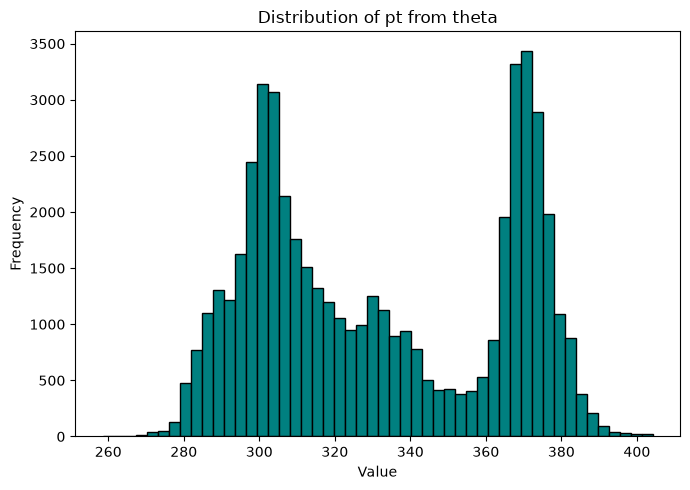

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 1, figsize=(7, 5))

# 1. Distribution Histogram (checks for skewness or weird data spikes)
axes.hist(data.ravel(), bins=50, color='teal', edgecolor='black')
axes.set_title(f"Distribution of {field_name} from theta")
axes.set_xlabel("Value")
axes.set_ylabel("Frequency")

plt.tight_layout()
plt.show()